In [1]:
%pip install ultralytics opencv-python matplotlib ipykernel

  Obtaining dependency information for ultralytics from https://files.pythonhosted.org/packages/d5/15/9843a1e0a100fc329f6545f9128d88a3ff172a2527a4111972c3ae568c13/ultralytics-8.4.190-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/47.0 kB ? eta -:--:--
     -------- ------------------------------- 10.2/47.0 kB ? eta -:--:--
     ---------------- --------------------- 20.5/47.0 kB 330.3 kB/s eta 0:00:01
     --------------------------------- ---- 41.0/47.0 kB 281.8 kB/s eta 0:00:01
     -------------------------------------- 47.0/47.0 kB 294.4 kB/s eta 0:00:00
  Obtaining dependency information for opencv-python from https://files.pythonhosted.org/packages/21/f0/9fa6e85cb10c8eb36a0222d27e50fe381b86ce49a55446bf39f491727564/opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/66/54/91fe3


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: d:\AIREI\Pillar_Angle_Detection\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.7 (tags/v3.11.7:fa7a6f2, Dec  4 2023, 19:24:49) [MSC v.1937 64 bit (AMD64)]
Python executable: d:\AIREI\Pillar_Angle_Detection\.venv\Scripts\python.exe


In [3]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
#Load your trained YOLOv8 model

model_path = r"D:\AIREI\Pillar_Angle_Detection\MODELS\best_pillar.pt"

model = YOLO(model_path)

print("Model loaded successfully!")
print("Model classes:", model.names)

Model loaded successfully!
Model classes: {0: 'Pillar'}


Image: pillar (17).jpeg
Class: Pillar
Confidence: 0.5193


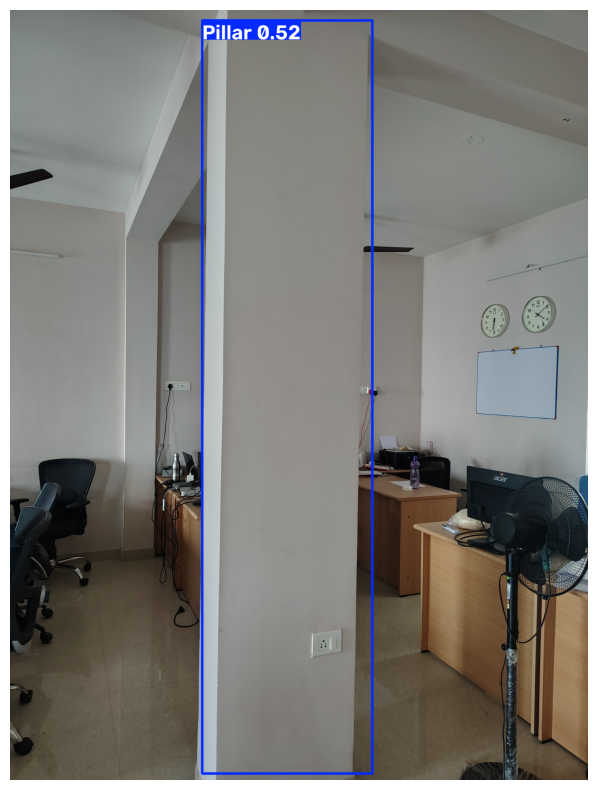

In [4]:
#Test the model with one image

# Enter your image path
image_path = r"D:\AIREI\Pillar_Angle_Detection\pillar_images\pillar (17).jpeg"

if not os.path.isfile(image_path):
    print("Image not found. Check the path.")
else:
    result = model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    print("Image:", os.path.basename(image_path))

    if len(result.boxes) > 0:
        for box in result.boxes:
            print("Class:", model.names[int(box.cls[0])])
            print("Confidence:", round(float(box.conf[0]), 4))
    else:
        print("No pillar detected.")

    img = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

Total images: 25

Image: pillar (1).jpeg
Pillar confidence: 0.4974


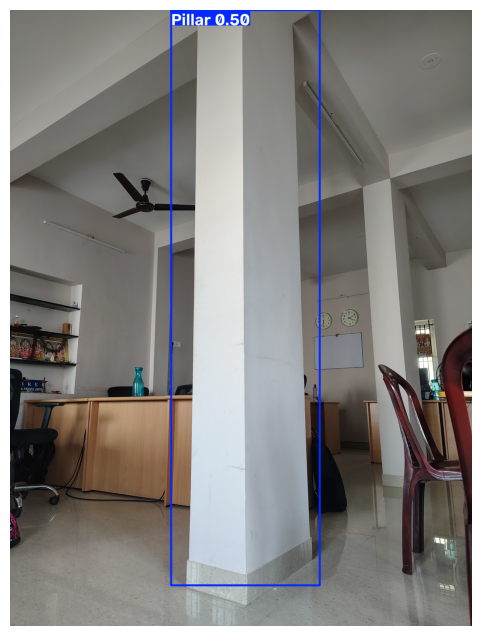


Image: pillar (10).jpeg
Pillar confidence: 0.5343


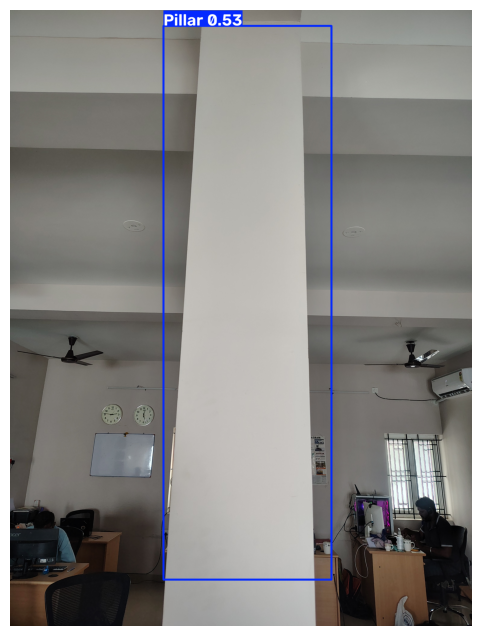


Image: pillar (11).jpeg
Pillar confidence: 0.3194


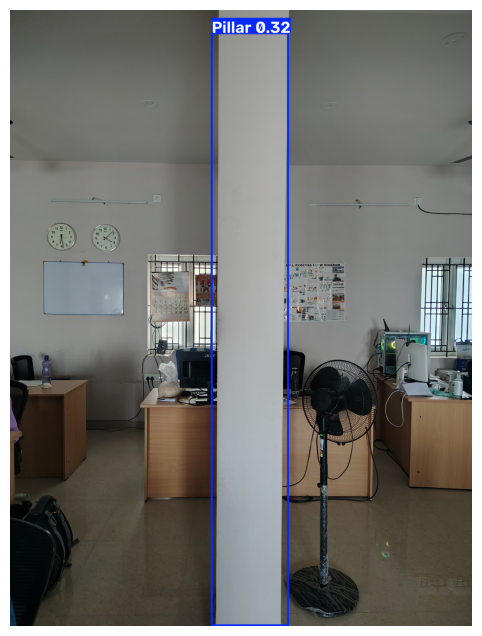


Image: pillar (12).jpeg
Pillar confidence: 0.6557


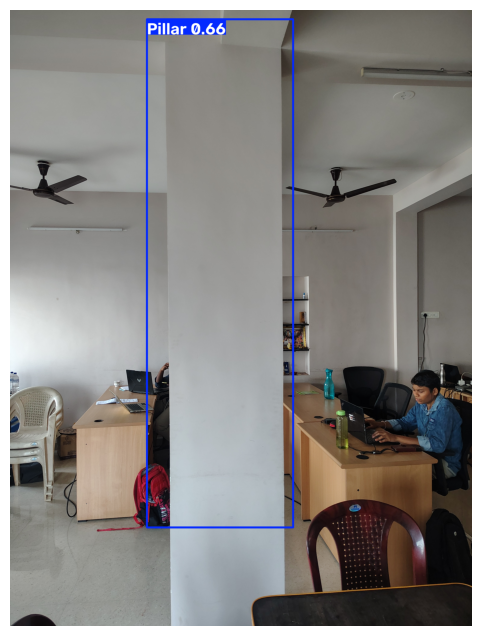


Image: pillar (13).jpeg
Pillar confidence: 0.3011


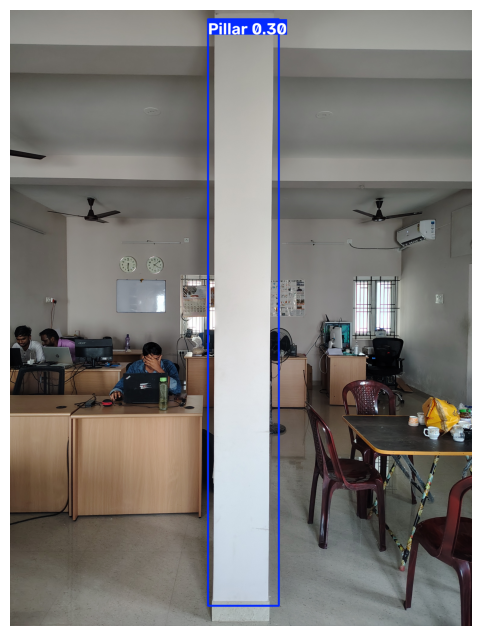


Image: pillar (14).jpeg
Pillar confidence: 0.4075


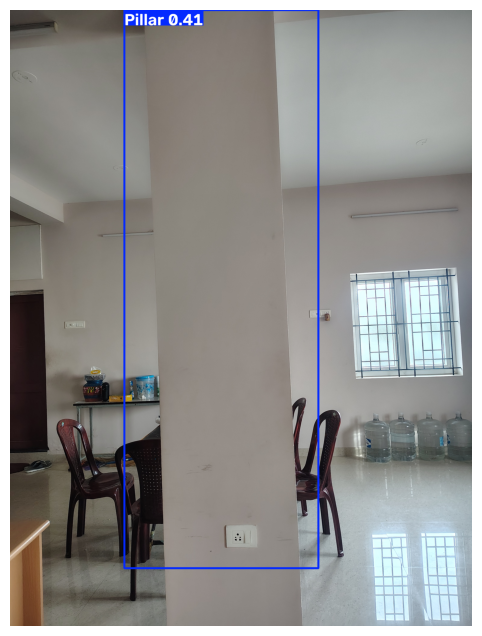


Image: pillar (15).jpeg
Pillar confidence: 0.6296


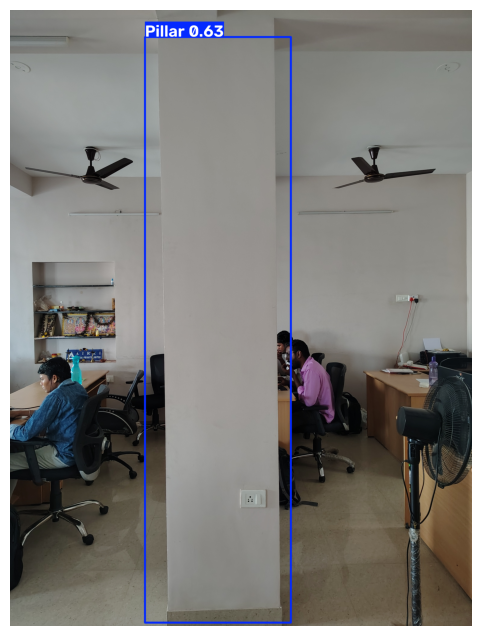


Image: pillar (16).jpeg
Pillar confidence: 0.5357


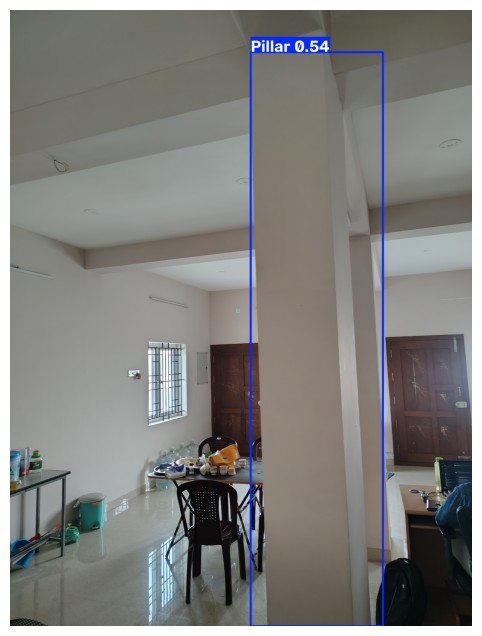


Image: pillar (17).jpeg
Pillar confidence: 0.5193


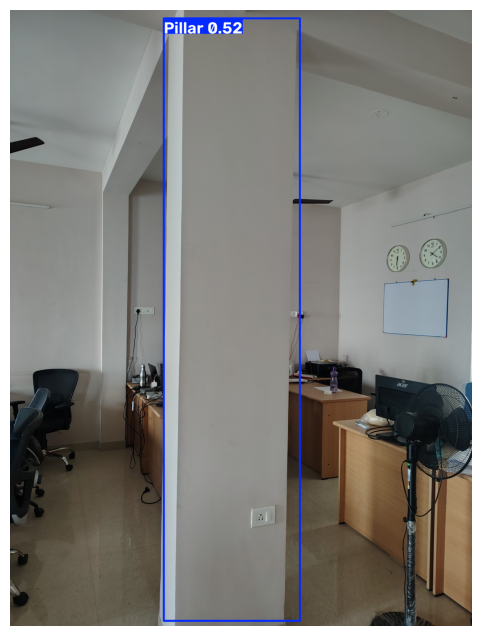


Image: pillar (18).jpeg
Pillar confidence: 0.7957


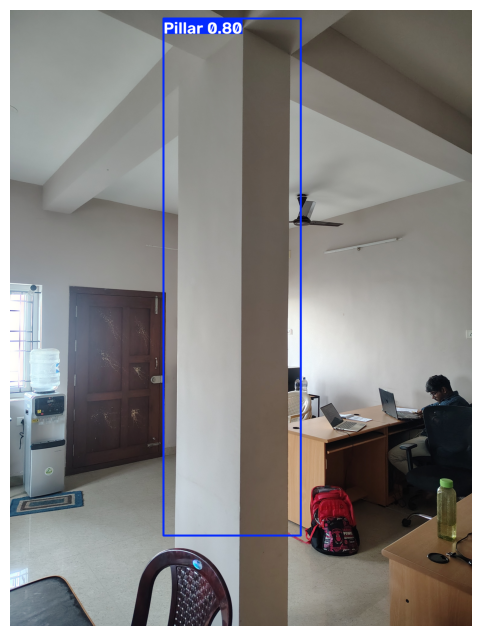


Image: pillar (19).jpeg
Pillar confidence: 0.4558


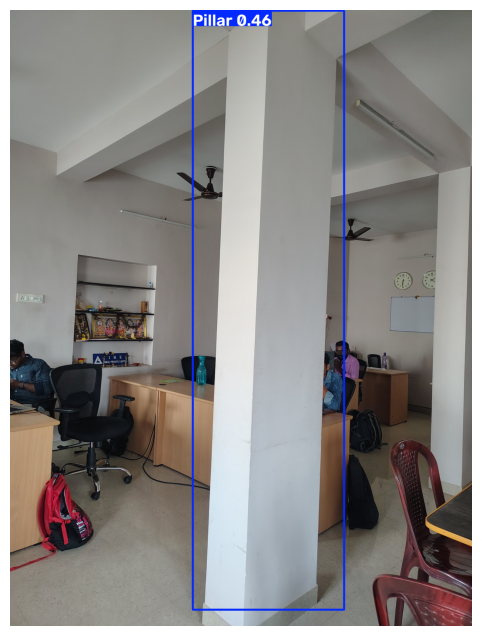


Image: pillar (2).jpeg
Pillar confidence: 0.3283


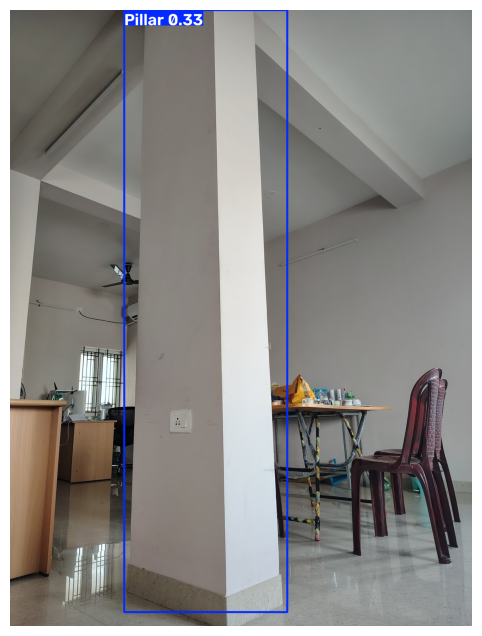


Image: pillar (20).jpeg
Pillar confidence: 0.597
Pillar confidence: 0.2896


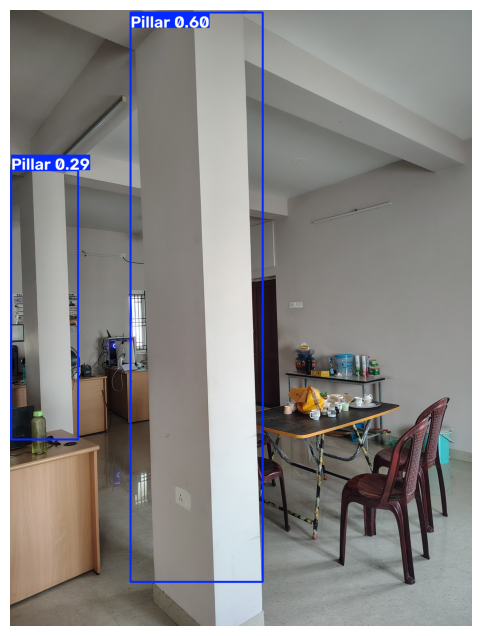


Image: pillar (21).jpeg
Pillar confidence: 0.4233


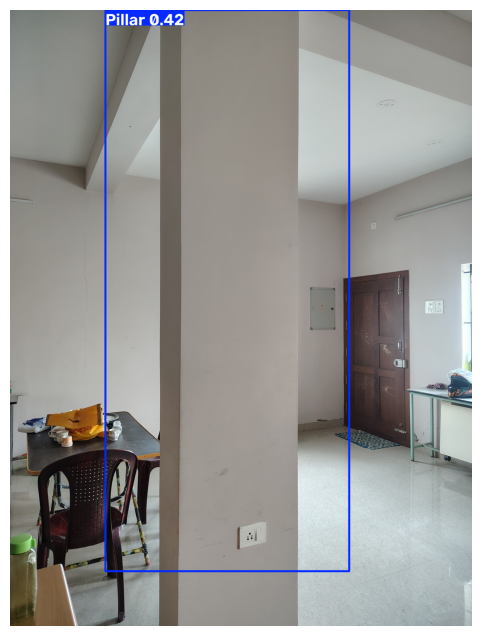


Image: pillar (22).jpeg
Pillar confidence: 0.7691


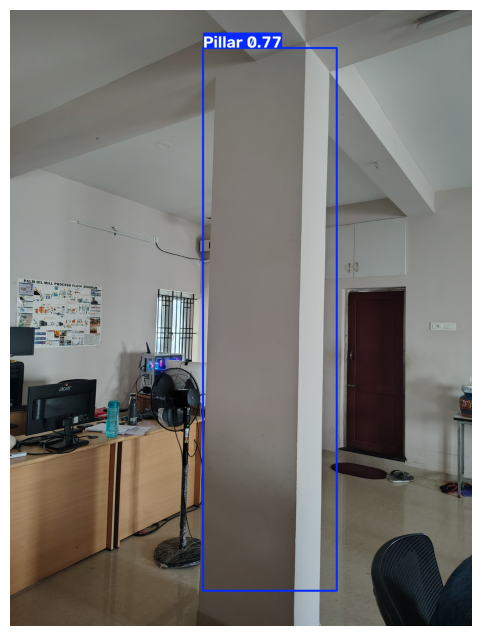


Image: pillar (23).jpeg
Pillar confidence: 0.4888


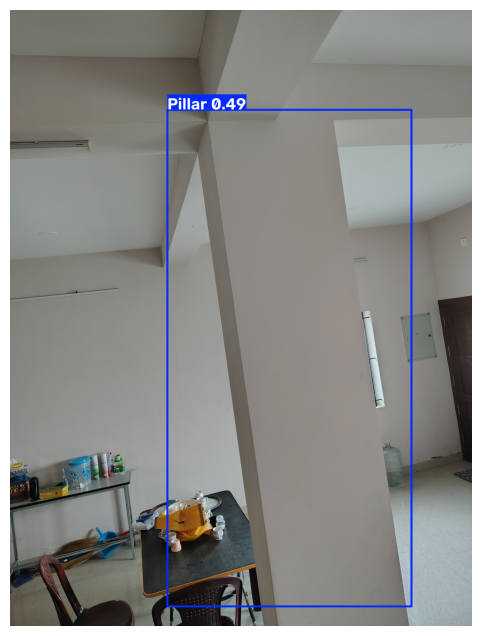


Image: pillar (24).jpeg
Pillar confidence: 0.6641


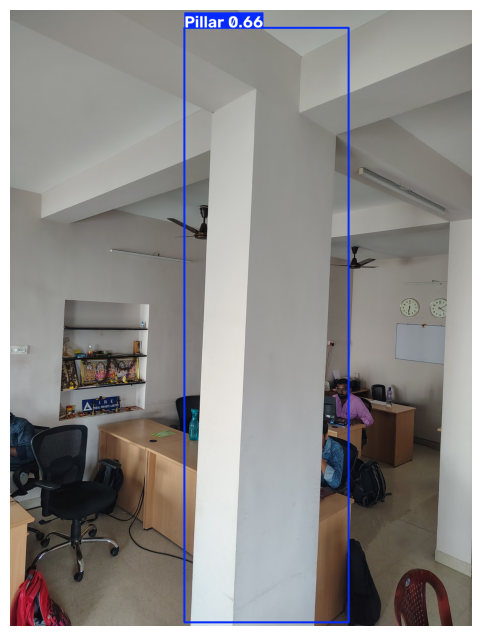


Image: pillar (25).jpeg
Pillar confidence: 0.5404


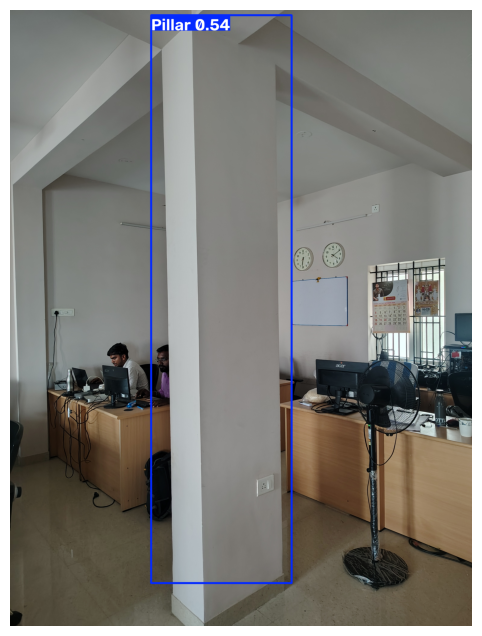


Image: pillar (3).jpeg
Pillar confidence: 0.8041


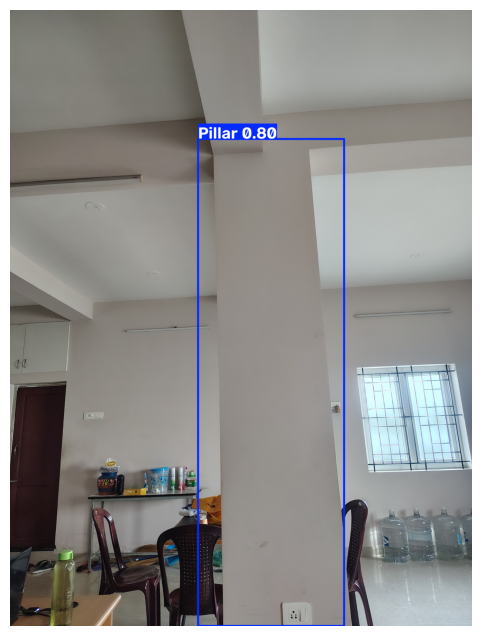


Image: pillar (4).jpeg
Pillar confidence: 0.6003


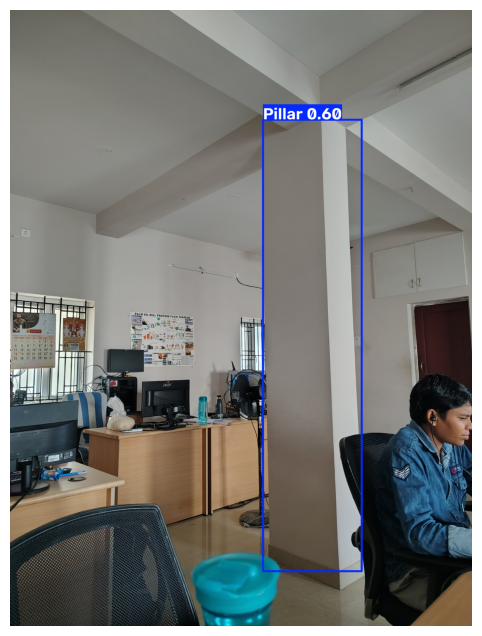


Image: pillar (5).jpeg
No pillar detected.


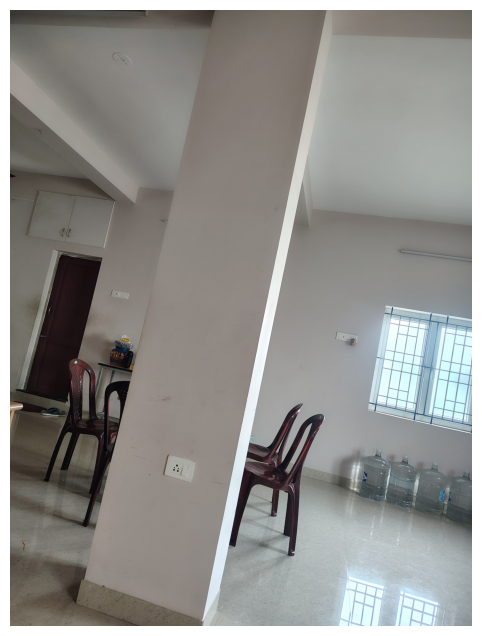


Image: pillar (6).jpeg
Pillar confidence: 0.653
Pillar confidence: 0.4591


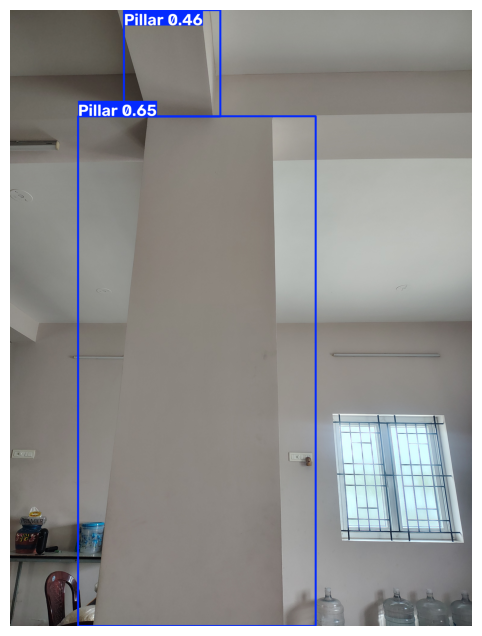


Image: pillar (7).jpeg
Pillar confidence: 0.6702


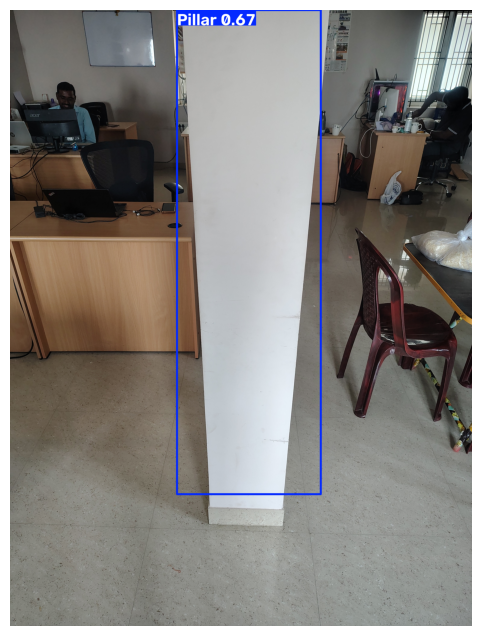


Image: pillar (8).jpeg
Pillar confidence: 0.6357


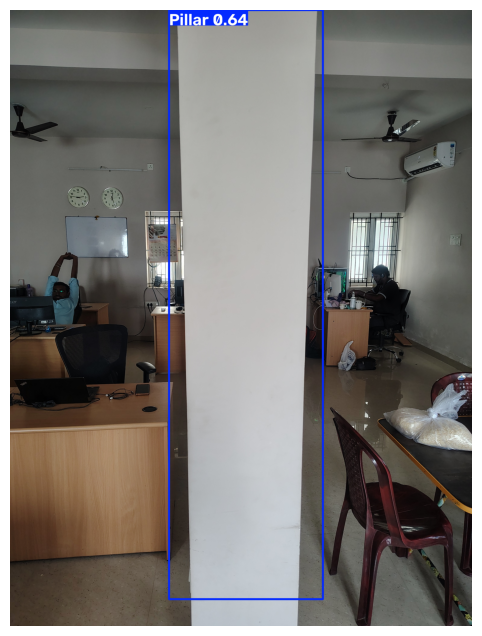


Image: pillar (9).jpeg
Pillar confidence: 0.4017


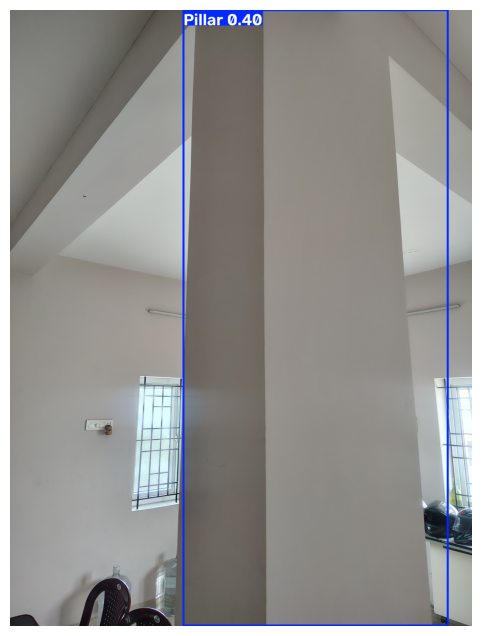

In [5]:
#Test multiple images

# Enter your image folder path
image_dir = r"D:\AIREI\Pillar_Angle_Detection\pillar_images"

extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp"]
image_paths = []

for ext in extensions:
    image_paths.extend(glob.glob(os.path.join(image_dir, ext)))

image_paths = sorted(image_paths)
print("Total images:", len(image_paths))

for path in image_paths:
    result = model.predict(
        source=path,
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    print("\nImage:", os.path.basename(path))

    if len(result.boxes) > 0:
        for box in result.boxes:
            print(
                "Pillar confidence:",
                round(float(box.conf[0]), 4)
            )
    else:
        print("No pillar detected.")

    img = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [5]:
#Test using your webcam 

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open webcam. Check camera connection.")
else:
    print("Webcam started. Press Q to stop.")

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                print("Cannot read webcam frame.")
                break

            result = model.predict(
                source=frame,
                imgsz=640,
                conf=0.25,
                verbose=False
            )[0]

            cv2.imshow("Pillar Detection", result.plot())

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()

Webcam started. Press Q to stop.


In [6]:
import cv2
import math
import numpy as np

# Camera configuration
VERTICAL_FOV_DEG = 50.0  # Replace with calibrated webcam vertical FOV
CONFIDENCE = 0.25

# Camera
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Cannot open webcam.")
else:
    zero_offset = 0.0
    angle_smooth = None

    print("Pillar angle detection started.")
    print("Press Z to set the current angle to zero.")
    print("Press Q to quit.")

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                print("Failed to read webcam.")
                break

            h, w = frame.shape[:2]

            # Image center and focal length
            cy = h / 2
            fy = (h / 2) / math.tan(
                math.radians(VERTICAL_FOV_DEG / 2)
            )

            # Detect pillar
            result = model.predict(
                source=frame,
                imgsz=640,
                conf=CONFIDENCE,
                verbose=False
            )[0]

            display = result.plot()

            if result.boxes is not None and len(result.boxes) > 0:
                # Select the highest-confidence detection
                idx = int(result.boxes.conf.argmax())
                box = result.boxes[idx]

                x1, y1, x2, y2 = map(
                    int, box.xyxy[0].tolist()
                )

                # Center of the detected pillar
                target_y = (y1 + y2) / 2

                # Vertical bearing relative to camera axis
                raw_angle = math.degrees(math.atan((target_y - cy) / fy))

                # Apply zero reference
                angle = raw_angle - zero_offset

                # Smooth small frame-to-frame changes
                if angle_smooth is None:
                    angle_smooth = angle
                else:
                    angle_smooth = (
                        0.8 * angle_smooth + 0.2 * angle
                    )

                cv2.line(
                    display, (0, int(cy)),
                    (w, int(cy)), (255, 255, 0), 1
                )

                cv2.circle(
                    display,
                    (int((x1 + x2) / 2), int(target_y)),
                    5, (0, 255, 255), -1
                )

                text = f"Vertical angle: {angle_smooth:+.2f} deg"

                cv2.putText(
                    display, text, (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, (0, 255, 0), 2
                )

                cv2.putText(
                    display, "Z: Set zero | Q: Quit",
                    (20, 75),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (255, 255, 255), 2
                )

            else:
                cv2.putText(
                    display, "Pillar not detected",
                    (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, (0, 0, 255), 2
                )

            cv2.imshow("Pillar Vertical Angle", display)

            key = cv2.waitKey(1) & 0xFF

            if key == ord("z") and (
                result.boxes is not None
                and len(result.boxes) > 0
            ):
                zero_offset = raw_angle
                angle_smooth = 0.0
                print("Zero reference set.")

            elif key == ord("q"):
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()

Pillar angle detection started.
Press Z to set the current angle to zero.
Press Q to quit.
Zero reference set.
Zero reference set.
Zero reference set.
